# Figure 6: Annual Event-Study Estimates by Topic Relevance Quartile

| Item | Description |
|---|---|
| Goal | Construct and export Figure 6 of the proposal (Panels A and B): Annual Event-Study Estimates by Topic Relevance Quartile. |
| Input | `sample_firm_privacy_patents.csv` and `firm_topic_relevance.csv` from `X1.1 - Data for Matching and Patent Analysis`. |
| Output | Figure 6 Panels A and B saved to `R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.3 - Figure 6 - Annual Event-Study Estimates by Topic Relevance Quartile`. Summary tables saved to `R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 6`. |
| Panels | **Panel A**: Event Study of Patenting Probability - Anonymizing or Decorrelating User Data (G06F 21/6254, H04W 12/033).<br>**Panel B**: Event Study of Patenting Probability - Tracking User Activity (H04L 67/535). |


## Step 1. Import packages and configure styling

Load standard data science and plotting libraries with publication styling.

In [1]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import Image, Markdown, display

# S3 Publication styling
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif", "serif"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.labelcolor"] = "#111111"
plt.rcParams["xtick.color"] = "#222222"
plt.rcParams["ytick.color"] = "#222222"

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 5.8
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")

# Color palette from X1.2.1
BLACK = "#000000"
BLUE = "#1E88E5"
GREY = "#5A6B7C"
CYAN = "#00ACC1"
MAROON = "#800000"
RED_ALL = "#B71C1C"

print("Setup completed successfully.")

Setup completed successfully.


## Step 2. Define file locations and group mappings

Configure paths for the topic relevance table, the patent dataset, and output directory.

In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[1]
DATA_FOLDER = PROJECT_FOLDER / "X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis"
PATENTS_CSV = DATA_FOLDER / "sample_firm_privacy_patents.csv"
RELEVANCE_CSV = DATA_FOLDER / "firm_topic_relevance.csv"

FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.3 - Figure 6 - Annual Event-Study Estimates by Topic Relevance Quartile"
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 6"
for folder in (FIGURE_FOLDER, TABLE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)

# CPC to Topic Group Mapping
GROUP_MAPPING_5 = {
    "G06Q30/0269": "Tracking User Profiles and Data",
    "G06Q30/0255": "Tracking User Profiles and Data",
    "G06Q30/0261": "Tracking User Profiles and Data",
    "H04W12/02":   "Protecting Privacy and Anonymity (PII)",
    "G06F21/6254": "Anonymizing or Decorrelating Data",
    "H04W12/033":  "Anonymizing or Decorrelating Data",
    "H04W12/03":   "Protecting Confidentiality (Encryption)",
    "H04L67/535":  "Tracking User Activity",
}

ORDER_5 = [
    "Tracking User Profiles and Data",
    "Protecting Privacy and Anonymity (PII)",
    "Anonymizing or Decorrelating Data",
    "Protecting Confidentiality (Encryption)",
    "Tracking User Activity",
]

LABELS_5 = [
    "Tracking User Profiles and Data (G06Q 30/0269, 30/0255, 30/0261)",
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)",
    "Anonymizing or Decorrelating Data (G06F 21/6254, H04W 12/033)",
    "Protecting Confidentiality by Encryption (H04W 12/03)",
    "Tracking User Activity (H04L 67/535)",
]

COLORS_5 = [BLACK, BLUE, GREY, CYAN, MAROON]
MARKERS_5 = ["o", "s", "^", "D", "v"]
STYLES_5 = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]

print(f"Data files:\n - {RELEVANCE_CSV}\n - {PATENTS_CSV}\nFigures: {FIGURE_FOLDER}\nTables: {TABLE_FOLDER}")


Data files:
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis/firm_topic_relevance.csv
 - /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/X1 - Example of Research Enabled by LLM Pipeline/X1.1 - Data for Matching and Patent Analysis/sample_firm_privacy_patents.csv
Figures: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.1 - Figures/R1.1.3 - X1 - Example of Research Enabled by LLM Pipeline/R1.1.3.3 - Figure 6 - Annual Event-Study Estimates by Topic Relevance Quartile
Tables: /Users/milanmiric/Documents/Research/Active Papers/LLM Text Sumarization and Data Extraction/R - Results/R1.2 - Tables/R1.2.2 - X1 - Example of Research Enabled by LLM Pipeline/R1.2.2.2 - X1.3 - Notebooks for Analysis/Figure 6


## Step 3. Load datasets and construct firm-level privacy patent counts

Load the 1,058 sample firms with their topic relevance scores (`cosine_policy_summary_firm_summary`), partition into quartiles ($Q_1$ to $Q_4$) and deciles ($D_1$ to $D_{10}$), and merge distinct patent counts for broad privacy patents and each narrow group.

In [3]:
# Load relevance
df_relevance = pd.read_csv(RELEVANCE_CSV)
assert len(df_relevance) == 1058, f"Expected 1,058 firms, got {len(df_relevance)}"

# Construct topic relevance quartiles
df_relevance["quartile"] = pd.qcut(
    df_relevance["cosine_policy_summary_firm_summary"],
    q=4,
    labels=["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]
)
q_bounds = [df_relevance["cosine_policy_summary_firm_summary"].min()] + list(
    df_relevance.groupby("quartile", observed=False)["cosine_policy_summary_firm_summary"].max()
)

# Construct topic relevance deciles
df_relevance["decile"] = pd.qcut(
    df_relevance["cosine_policy_summary_firm_summary"],
    q=10,
    labels=[f"D{i}" for i in range(1, 11)]
)

# Load patent dataset
df_patents = pd.read_csv(PATENTS_CSV)
df_patents["filing_date"] = pd.to_datetime(df_patents["filing_date"])
df_patents["filing_year"] = df_patents["filing_date"].dt.year

# 1. Broad definition: Any privacy patent
all_firm_pats = df_patents.groupby("gvkey")["patent_num"].nunique().rename("patents_broad_all")

# 2. Narrow groups
g1_pats = df_patents[df_patents["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_1")
g2_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/02"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_2")
g3_pats = df_patents[df_patents["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])].groupby("gvkey")["patent_num"].nunique().rename("patents_group_3")
g4_pats = df_patents[df_patents["privacy_cpc"] == "H04W12/03"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_4")
g5_pats = df_patents[df_patents["privacy_cpc"] == "H04L67/535"].groupby("gvkey")["patent_num"].nunique().rename("patents_group_5")

# Combined data and customer tracking patents (G06Q + H04L 67/535)
track_comb_pats = df_patents[df_patents["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261", "H04L67/535"])].groupby("gvkey")["patent_num"].nunique().rename("patents_tracking_combined")

# Merge into comprehensive firm table
df_firm = df_relevance.copy()
for s in [all_firm_pats, g1_pats, g2_pats, g3_pats, g4_pats, g5_pats, track_comb_pats]:
    df_firm = df_firm.merge(s, on="gvkey", how="left")

patent_cols = ["patents_broad_all", "patents_group_1", "patents_group_2", "patents_group_3", "patents_group_4", "patents_group_5", "patents_tracking_combined"]
df_firm[patent_cols] = df_firm[patent_cols].fillna(0)

# Summary table by quartile
quartile_summary = df_firm.groupby("quartile", observed=False).agg(
    n_firms=("gvkey", "count"),
    relevance_min=("cosine_policy_summary_firm_summary", "min"),
    relevance_mean=("cosine_policy_summary_firm_summary", "mean"),
    relevance_max=("cosine_policy_summary_firm_summary", "max"),
    avg_broad_patents=("patents_broad_all", "mean"),
    avg_group_1=("patents_group_1", "mean"),
    avg_group_2=("patents_group_2", "mean"),
    avg_group_3=("patents_group_3", "mean"),
    avg_group_4=("patents_group_4", "mean"),
    avg_group_5=("patents_group_5", "mean"),
    avg_tracking_combined=("patents_tracking_combined", "mean"),
).reset_index()

quartile_summary.to_csv(TABLE_FOLDER / "firm_topic_relevance_quartile_summary.csv", index=False)
display(quartile_summary)

,quartile,n_firms,relevance_min,relevance_mean,relevance_max,avg_broad_patents,avg_group_1,avg_group_2,avg_group_3,avg_group_4,avg_group_5,avg_tracking_combined
0,Q1 (Lowest Relevance),265,0.403442,0.467629,0.486179,2.207547,0.177358,0.064151,0.075472,0.007547,0.026415,0.200000
1,Q2,264,0.486222,0.498360,0.510579,3.060606,0.231061,0.155303,0.102273,0.022727,0.003788,0.234848
2,Q3,264,0.510582,0.523013,0.536647,11.924242,1.390152,0.321970,0.393939,0.053030,0.140152,1.526515
3,Q4 (Highest Relevance),265,0.536715,0.559407,0.620883,111.113208,8.637736,5.192453,3.030189,0.452830,1.166038,9.747170


## Step 5. Construct Pre- and Post-2016 panel dataset (2009–2020)

Restrict the patent data to the requested **2009 to 2020** period. Define Pre-2016 as 2009–2015 (7 years) and Post-2016 as 2016–2020 (5 years), computing annual patent rates and standard errors for each topic category, quartile, and decile.

In [4]:
# Restrict to 2009-2020 window
WINDOW_START, WINDOW_END = 2009, 2020
pats_win = df_patents[df_patents["filing_year"].between(WINDOW_START, WINDOW_END)].copy()

categories_dict = {
    "Tracking User Profiles and Data (G06Q)": (
        BLACK, "o", "-",
        pats_win[pats_win["privacy_cpc"].isin(["G06Q30/0269", "G06Q30/0255", "G06Q30/0261"])],
    ),
    "Protecting Privacy and Anonymity (PII) (H04W 12/02)": (
        BLUE, "s", "--",
        pats_win[pats_win["privacy_cpc"] == "H04W12/02"],
    ),
    "Anonymizing or Decorrelating Data (G06F/H04W)": (
        GREY, "^", "-.",
        pats_win[pats_win["privacy_cpc"].isin(["G06F21/6254", "H04W12/033"])],
    ),
    "Protecting Confidentiality by Encryption (H04W 12/03)": (
        CYAN, "D", ":",
        pats_win[pats_win["privacy_cpc"] == "H04W12/03"],
    ),
    "Tracking User Activity (H04L 67/535)": (
        MAROON, "v", (0, (3, 1, 1, 1)),
        pats_win[pats_win["privacy_cpc"] == "H04L67/535"],
    ),
}

# Construct period indicator
pats_win["period"] = np.where(pats_win["filing_year"] < 2016, "Pre", "Post")
pats_win_firm = pats_win.copy()


## Step 8. Figure 6: Event study of anonymizing or decorrelating patenting probability by quartile

Coefficient plot tracking the year-by-year change in the probability of a firm filing at least one patent in Anonymizing or Decorrelating technologies (`G06F 21/6254`, `H04W 12/033`) relative to 2015 across each topic relevance quartile ($Q_1$ to $Q_4$). Red dashed background lines indicate the 2015/2016 policy transition and 2018/2019 GDPR milestone.

**Figure 6. Probability of Patenting Anonymizing or Decorrelating Technology Relative to 2015 by Topic Relevance Quartile**

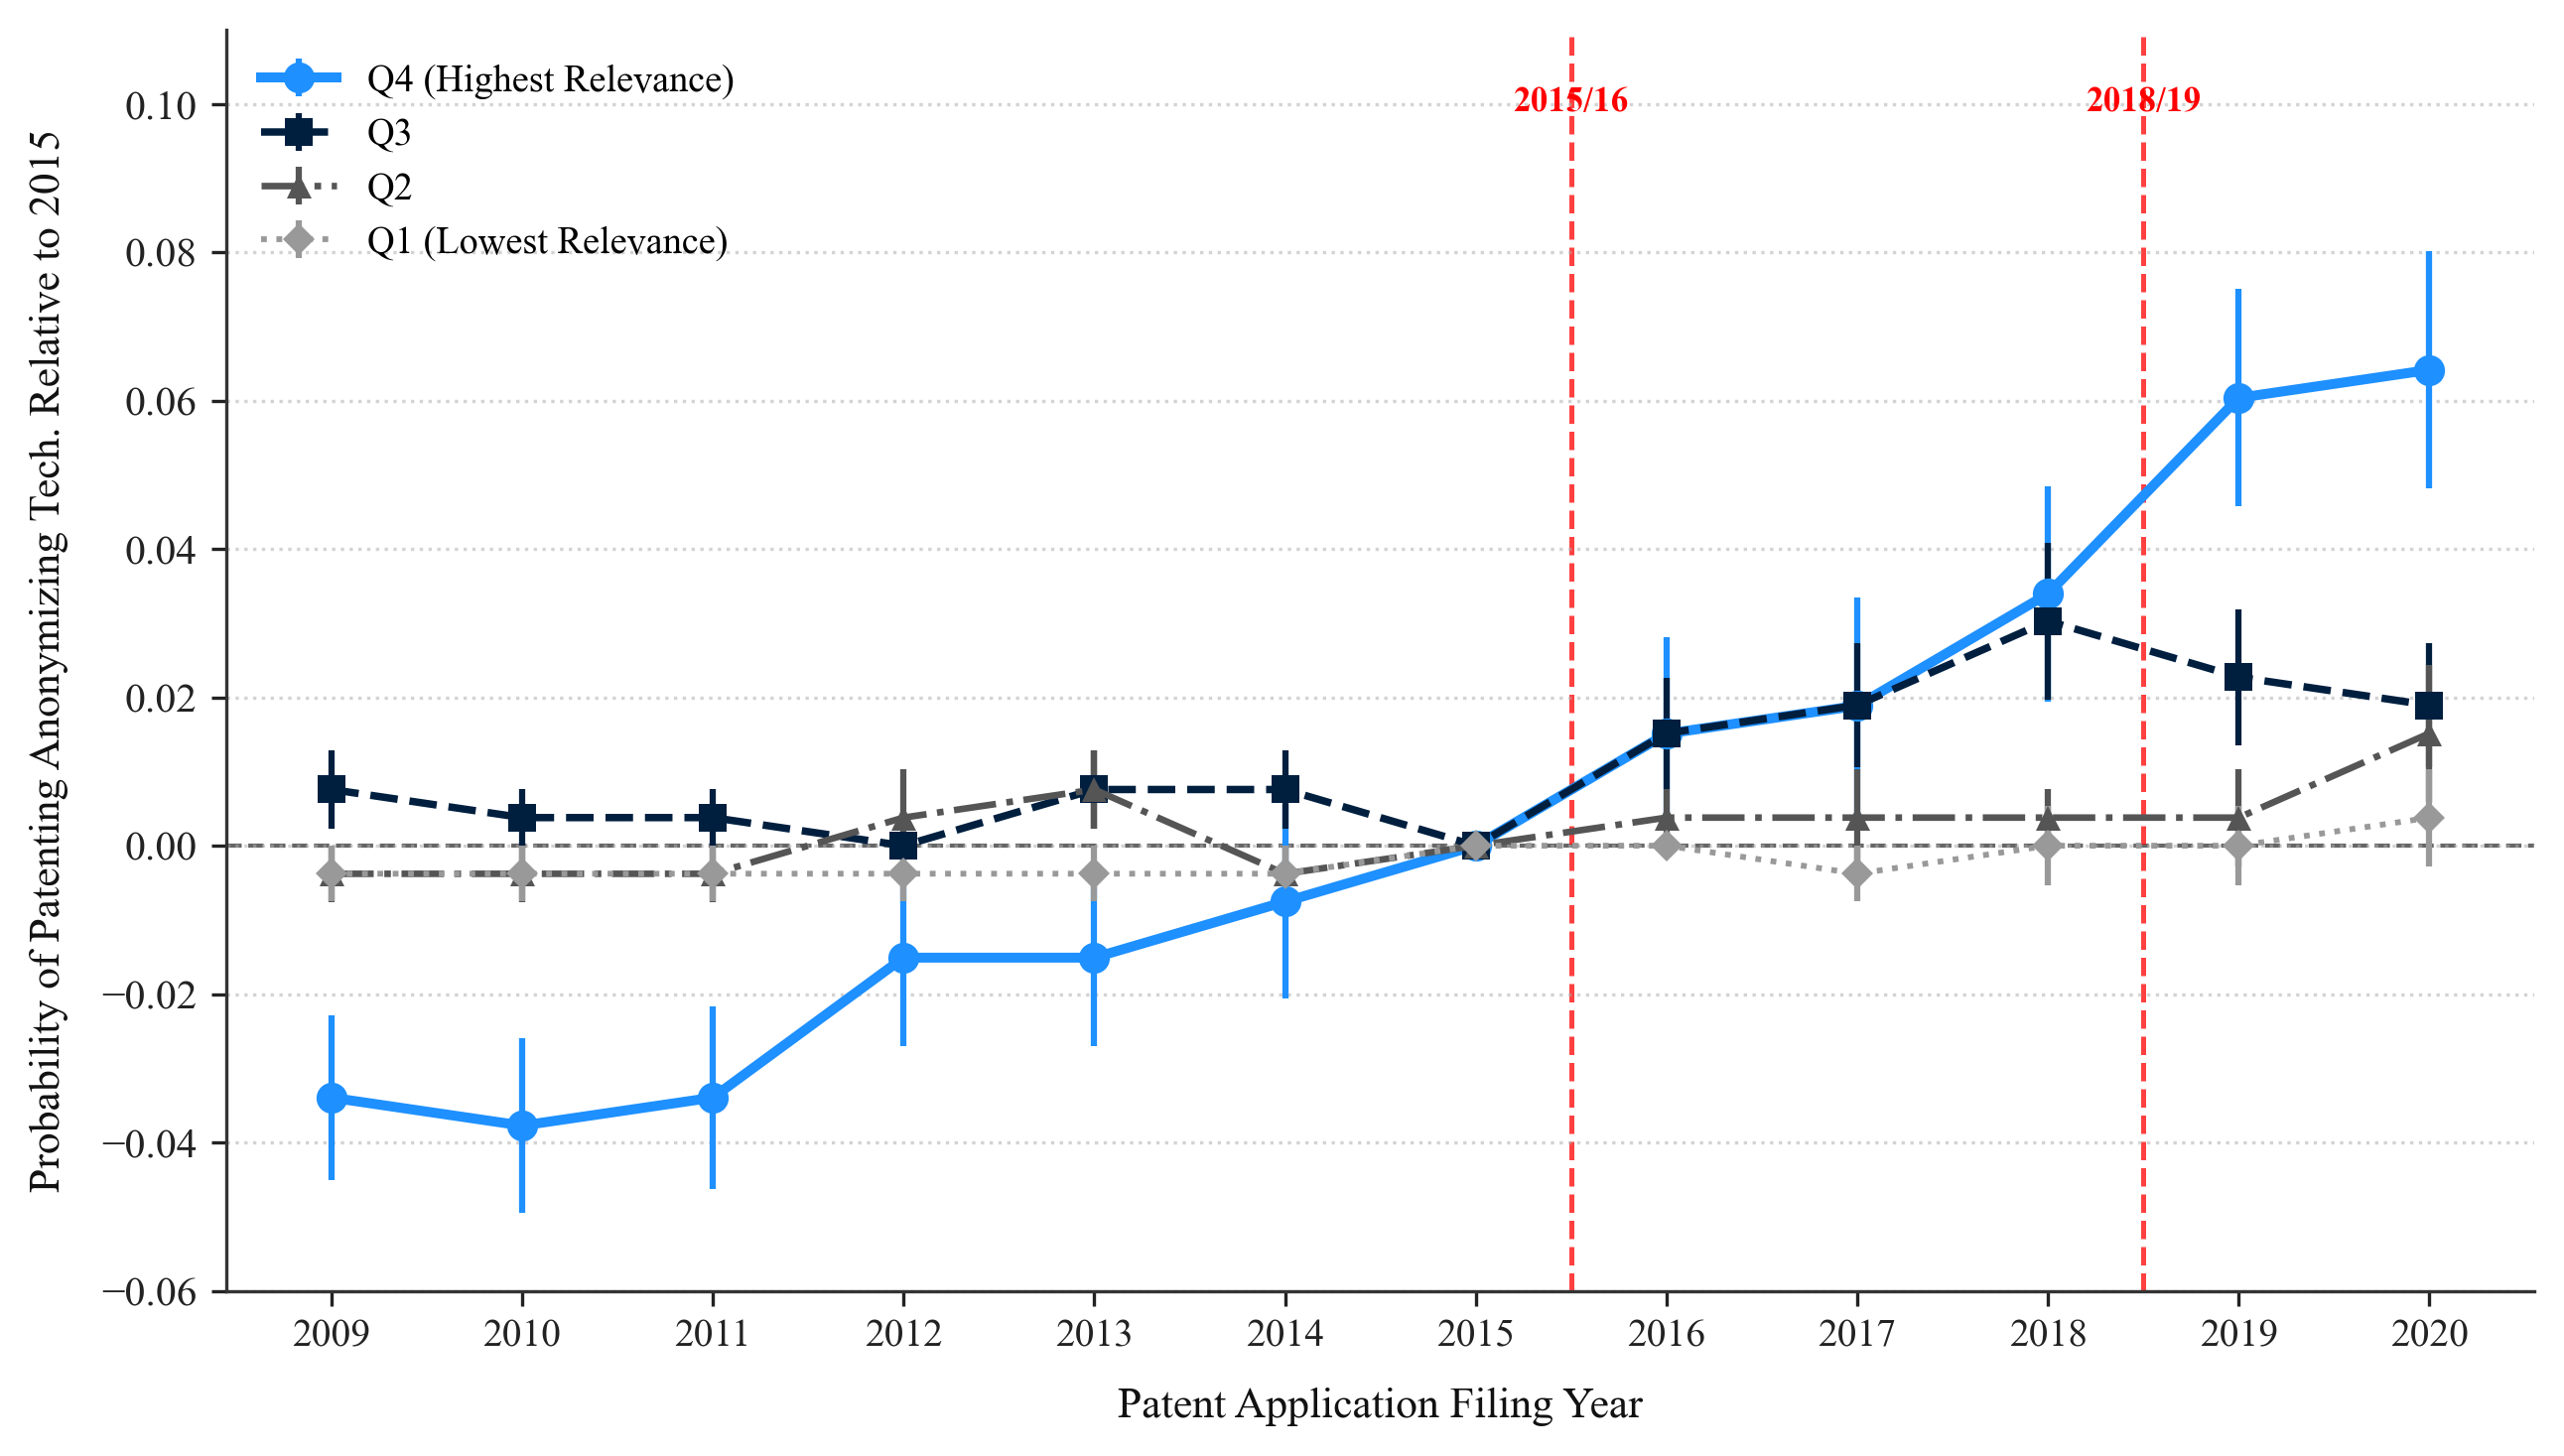

*Notes*: Event study coefficient plot tracking the annual probability that a firm files at least one patent in Anonymizing or Decorrelating technologies (CPC codes G06F 21/6254, H04W 12/033) relative to 2015 across topic relevance quartiles ($Q_1$ to $Q_4$). Vertical red dashed background lines mark the 2015/2016 policy transition and the 2018/2019 GDPR enforcement milestone. For Q4 firms (dodger blue), the probability of patenting anonymizing technology surged by +6.0 percentage points in 2019 and +6.4 percentage points in 2020 relative to 2015.

In [5]:
figure_name = "fig_6_event_study_anonymizing_by_quartile"
figure_title = "Figure 6. Probability of Patenting Anonymizing or Decorrelating Technology Relative to 2015 by Topic Relevance Quartile"

anon_codes = ["G06F21/6254", "H04W12/033"]
anon_pats = df_patents[df_patents["privacy_cpc"].isin(anon_codes)].copy()

years = list(range(2009, 2021))
gvkeys = df_firm["gvkey"].unique()

panel = pd.MultiIndex.from_product([gvkeys, years], names=["gvkey", "year"]).to_frame().reset_index(drop=True)
panel = panel.merge(df_firm[["gvkey", "quartile", "decile"]], on="gvkey", how="left")

fy_anon = anon_pats.groupby(["gvkey", "filing_year"])["patent_num"].nunique().reset_index()
fy_anon.columns = ["gvkey", "year", "n_anon_patents"]
panel = panel.merge(fy_anon, on=["gvkey", "year"], how="left")
panel["n_anon_patents"] = panel["n_anon_patents"].fillna(0)
panel["has_anon_patent"] = (panel["n_anon_patents"] > 0).astype(float)

p_matrix = panel.pivot(index="gvkey", columns="year", values="has_anon_patent")
p_matrix = p_matrix.merge(df_firm.set_index("gvkey")[["quartile", "decile"]], left_index=True, right_index=True)

diff_matrix = p_matrix[years].subtract(p_matrix[2015], axis=0)
diff_matrix["quartile"] = p_matrix["quartile"]
diff_matrix["decile"] = p_matrix["decile"]

# Export table of event study estimates
event_study_rows = []
for q in ["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]:
    sub = diff_matrix[diff_matrix["quartile"] == q][years]
    means = sub.mean()
    ses = sub.sem()
    for y in years:
        event_study_rows.append({
            "quartile": q,
            "year": y,
            "coef_rel_2015": means[y],
            "se": ses[y],
            "ci_lo": means[y] - 1.96 * ses[y],
            "ci_hi": means[y] + 1.96 * ses[y],
        })
df_event_study = pd.DataFrame(event_study_rows)
df_event_study.to_csv(TABLE_FOLDER / "event_study_anonymizing_by_quartile.csv", index=False)

fig, ax = plt.subplots(figsize=(10.0, 5.5))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

ax.axhline(0, color="#666666", linestyle="--", linewidth=1.0, zorder=1)
ax.axvline(2015.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75, zorder=1)
ax.axvline(2018.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75, zorder=1)

q_styles = {
    "Q4 (Highest Relevance)": ("dodgerblue", "o", "-", 2.4, 7.5, "Q4 (Highest Relevance)"),
    "Q3": ("#001F3F", "s", "--", 1.8, 6.5, "Q3"),
    "Q2": ("#555555", "^", "-.", 1.6, 6.0, "Q2"),
    "Q1 (Lowest Relevance)": ("#999999", "D", ":", 1.4, 5.5, "Q1 (Lowest Relevance)"),
}

for q_lbl, (color, marker, lstyle, lwidth, msize, display_lbl) in q_styles.items():
    sub = diff_matrix[diff_matrix["quartile"] == q_lbl][years]
    means = sub.mean()
    ses = sub.sem()
    ax.errorbar(
        years, means, yerr=ses,
        fmt=marker, color=color, linestyle=lstyle, linewidth=lwidth,
        ecolor=color, elinewidth=1.5, capsize=0, markersize=msize,
        markeredgewidth=0, label=display_lbl, zorder=5
    )

ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=9.5)
ax.set_xlabel("Patent Application Filing Year", fontsize=10.5, labelpad=8)
ax.set_ylabel("Probability of Patenting Anonymizing Tech. Relative to 2015", fontsize=10.5, labelpad=8)
ax.set_ylim(-0.06, 0.11)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

ax.text(2015.5, 0.098, "2015/16", ha="center", va="bottom", fontsize=8.5, color="red", fontweight="bold")
ax.text(2018.5, 0.098, "2018/19", ha="center", va="bottom", fontsize=8.5, color="red", fontweight="bold")
ax.legend(loc="upper left", frameon=False, fontsize=9.2)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_FOLDER / f"1 - Figure 6 Panel A - Event Study of Patenting Probability - Anonymizing Data.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
plt.close(fig)

notes_fig6 = (
    "Event study coefficient plot tracking the annual probability that a firm files at least one patent in Anonymizing or Decorrelating "
    "technologies (CPC codes G06F 21/6254, H04W 12/033) relative to 2015 across topic relevance quartiles ($Q_1$ to $Q_4$). "
    "Vertical red dashed background lines mark the 2015/2016 policy transition and the 2018/2019 GDPR enforcement milestone. "
    "For Q4 firms (dodger blue), the probability of patenting anonymizing technology surged by +6.0 percentage points in 2019 and +6.4 percentage points in 2020 relative to 2015."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig6}"))


## Step 9. Figure 7: Event study of tracking user activity patenting probability by quartile

Event study coefficient plot tracking the annual probability of a firm filing at least one patent in Tracking User Activity technologies (`H04L 67/535`) relative to 2015 across each topic relevance quartile ($Q_1$ to $Q_4$). Red dashed background lines indicate the 2015/2016 policy transition and 2018/2019 GDPR milestone.

**Figure 7. Probability of Patenting Tracking User Activity Technology Relative to 2015 by Topic Relevance Quartile**

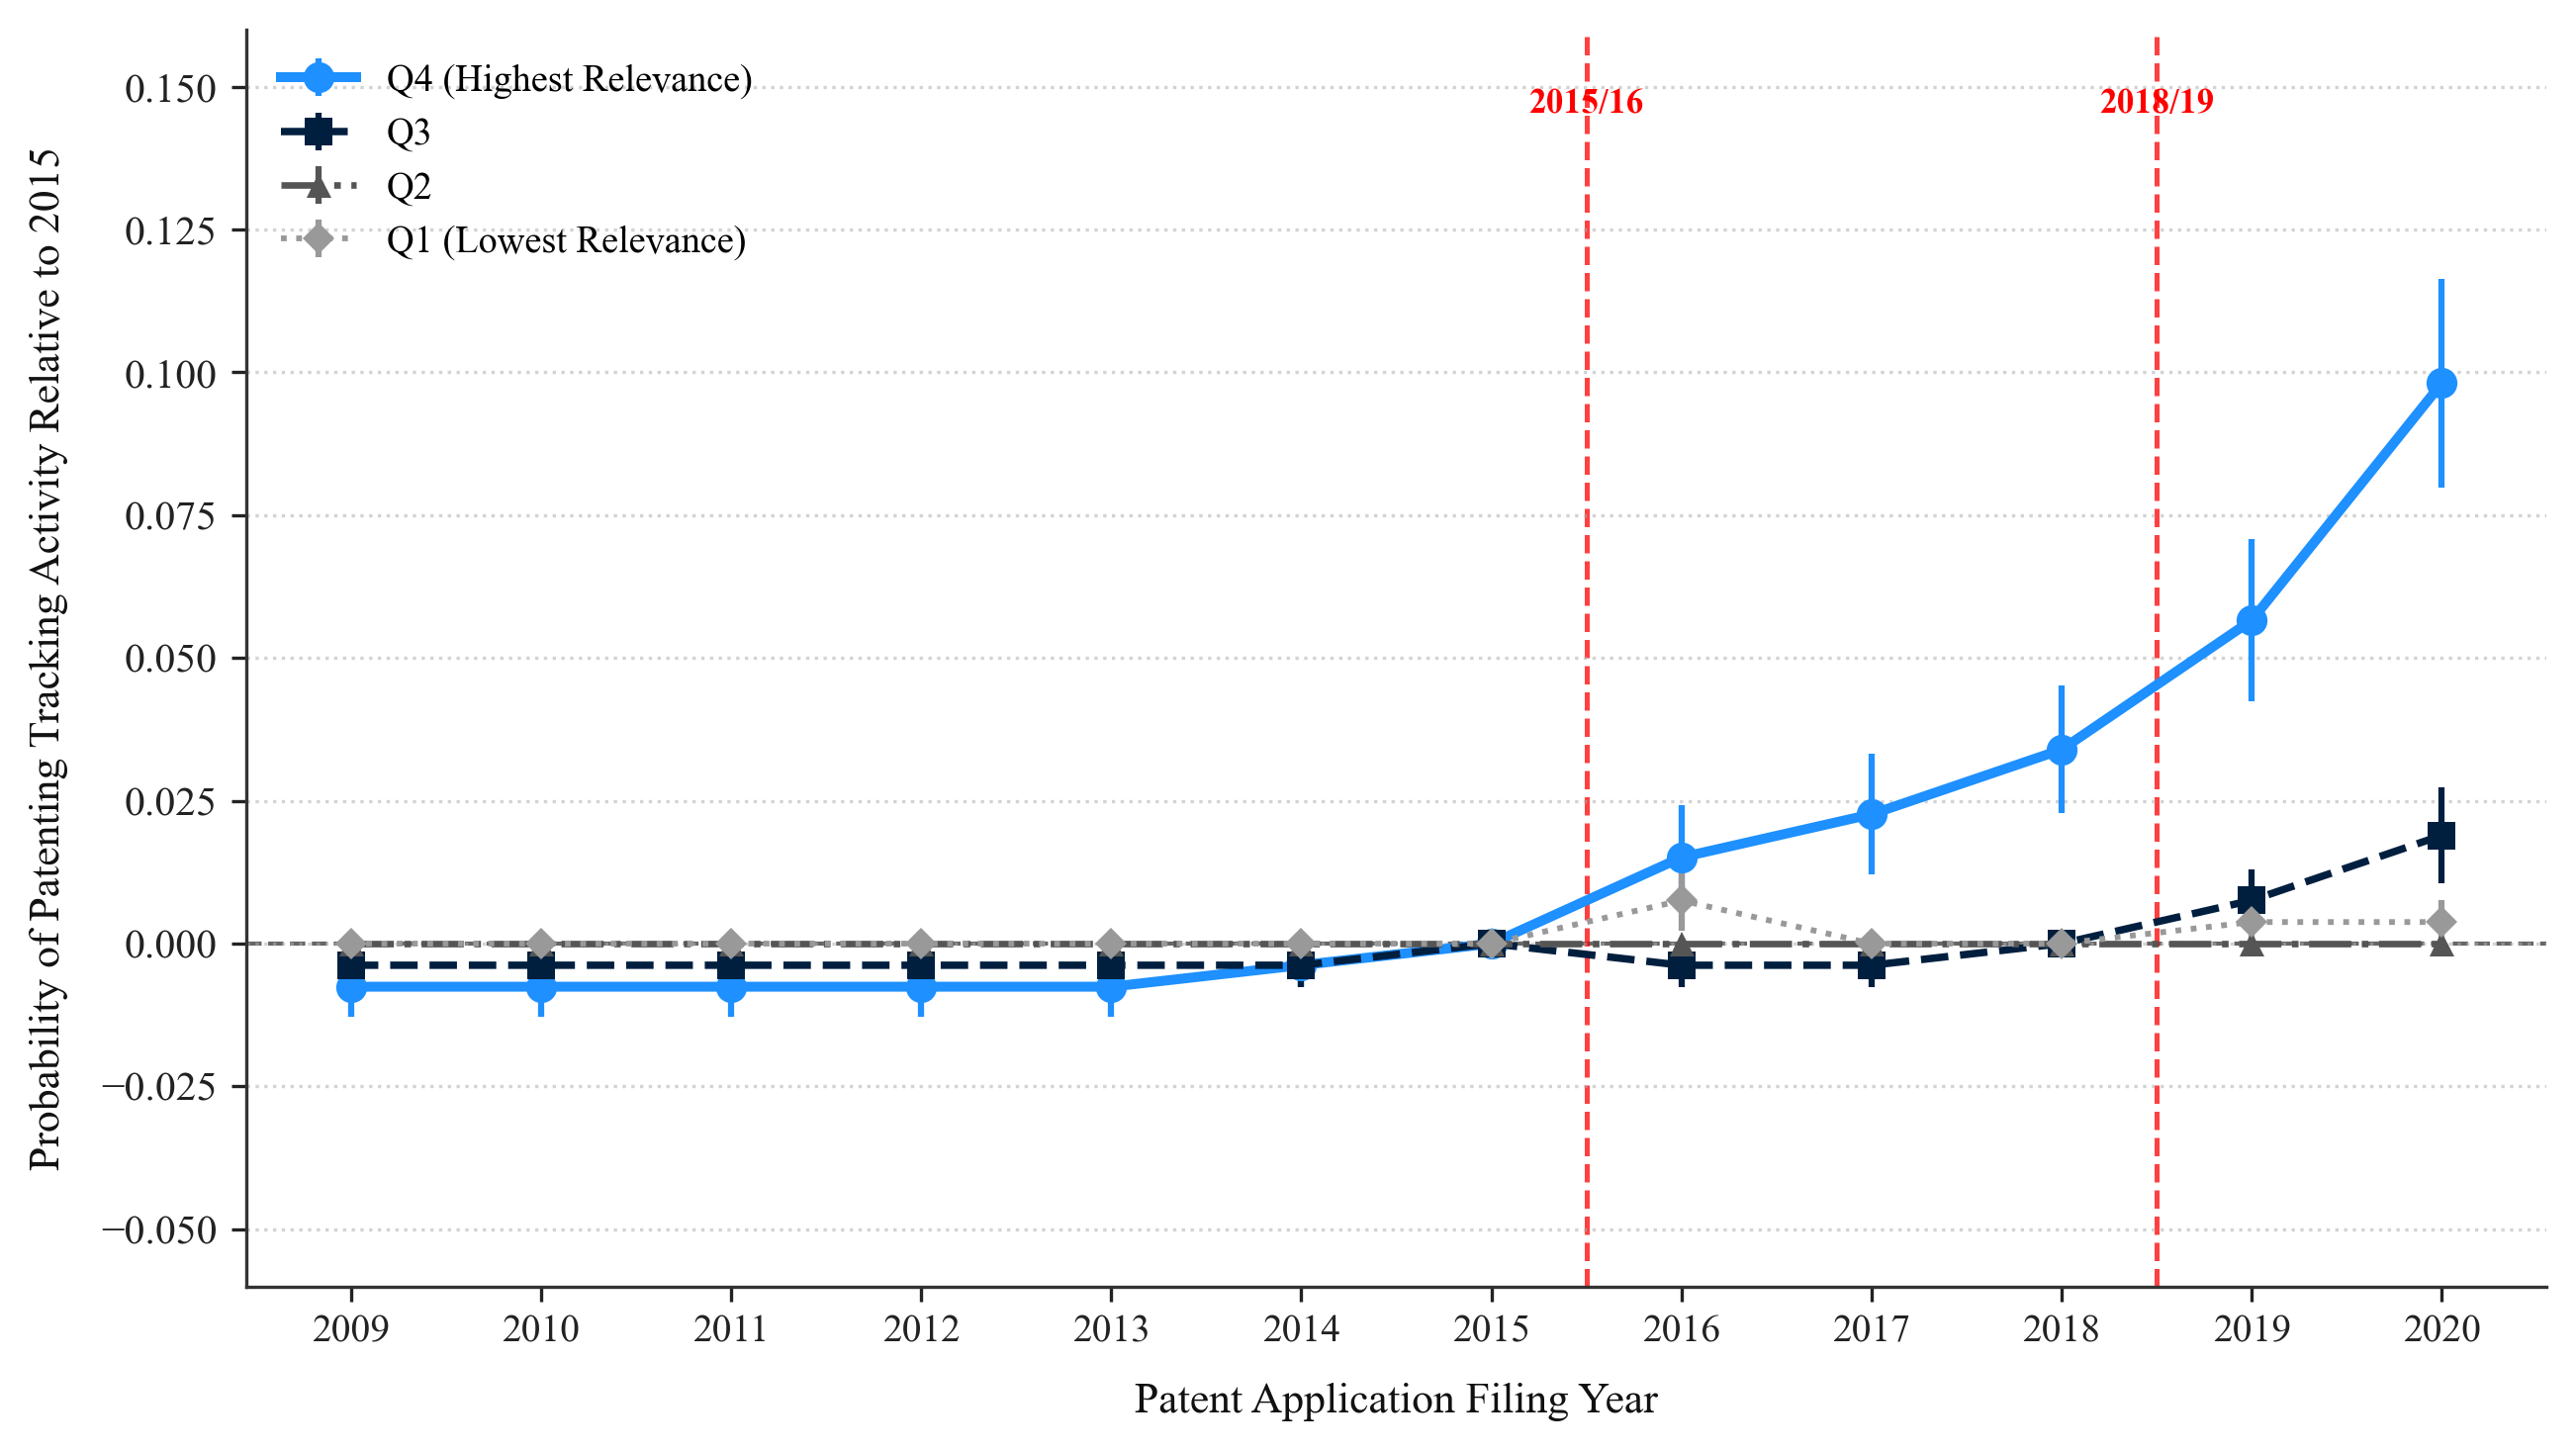

*Notes*: Event study coefficient plot tracking the annual probability that a firm files at least one patent in Tracking User Activity technologies (CPC code H04L 67/535) relative to 2015 across topic relevance quartiles ($Q_1$ to $Q_4$). Vertical red dashed background lines mark the 2015/2016 policy transition and the 2018/2019 GDPR enforcement milestone. For Q4 firms (dodger blue), the probability of patenting tracking user activity technology grew steadily post-2016, surging to +5.7 percentage points in 2019 and +9.8 percentage points in 2020 relative to 2015.

In [6]:
figure_name = "fig_7_event_study_tracking_activity_by_quartile"
figure_title = "Figure 7. Probability of Patenting Tracking User Activity Technology Relative to 2015 by Topic Relevance Quartile"

tracking_codes = ["H04L67/535"]
tracking_pats = df_patents[df_patents["privacy_cpc"].isin(tracking_codes)].copy()

years = list(range(2009, 2021))
gvkeys = df_firm["gvkey"].unique()

panel_track = pd.MultiIndex.from_product([gvkeys, years], names=["gvkey", "year"]).to_frame().reset_index(drop=True)
panel_track = panel_track.merge(df_firm[["gvkey", "quartile", "decile"]], on="gvkey", how="left")

fy_track = tracking_pats.groupby(["gvkey", "filing_year"])["patent_num"].nunique().reset_index()
fy_track.columns = ["gvkey", "year", "n_tracking_patents"]
panel_track = panel_track.merge(fy_track, on=["gvkey", "year"], how="left")
panel_track["n_tracking_patents"] = panel_track["n_tracking_patents"].fillna(0)
panel_track["has_tracking_patent"] = (panel_track["n_tracking_patents"] > 0).astype(float)

p_matrix_track = panel_track.pivot(index="gvkey", columns="year", values="has_tracking_patent")
p_matrix_track = p_matrix_track.merge(df_firm.set_index("gvkey")[["quartile", "decile"]], left_index=True, right_index=True)

diff_matrix_track = p_matrix_track[years].subtract(p_matrix_track[2015], axis=0)
diff_matrix_track["quartile"] = p_matrix_track["quartile"]
diff_matrix_track["decile"] = p_matrix_track["decile"]

# Export table of event study estimates
event_study_track_rows = []
for q in ["Q1 (Lowest Relevance)", "Q2", "Q3", "Q4 (Highest Relevance)"]:
    sub = diff_matrix_track[diff_matrix_track["quartile"] == q][years]
    means = sub.mean()
    ses = sub.sem()
    for y in years:
        event_study_track_rows.append({
            "quartile": q,
            "year": y,
            "coef_rel_2015": means[y],
            "se": ses[y],
            "ci_lo": means[y] - 1.96 * ses[y],
            "ci_hi": means[y] + 1.96 * ses[y],
        })
df_event_study_track = pd.DataFrame(event_study_track_rows)
df_event_study_track.to_csv(TABLE_FOLDER / "event_study_tracking_activity_by_quartile.csv", index=False)

fig, ax = plt.subplots(figsize=(10.0, 5.5))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

ax.axhline(0, color="#666666", linestyle="--", linewidth=1.0, zorder=1)
ax.axvline(2015.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75, zorder=1)
ax.axvline(2018.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75, zorder=1)

q_styles = {
    "Q4 (Highest Relevance)": ("dodgerblue", "o", "-", 2.4, 7.5, "Q4 (Highest Relevance)"),
    "Q3": ("#001F3F", "s", "--", 1.8, 6.5, "Q3"),
    "Q2": ("#555555", "^", "-.", 1.6, 6.0, "Q2"),
    "Q1 (Lowest Relevance)": ("#999999", "D", ":", 1.4, 5.5, "Q1 (Lowest Relevance)"),
}

for q_lbl, (color, marker, lstyle, lwidth, msize, display_lbl) in q_styles.items():
    sub = diff_matrix_track[diff_matrix_track["quartile"] == q_lbl][years]
    means = sub.mean()
    ses = sub.sem()
    ax.errorbar(
        years, means, yerr=ses,
        fmt=marker, color=color, linestyle=lstyle, linewidth=lwidth,
        ecolor=color, elinewidth=1.5, capsize=0, markersize=msize,
        markeredgewidth=0, label=display_lbl, zorder=5
    )

ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=9.5)
ax.set_xlabel("Patent Application Filing Year", fontsize=10.5, labelpad=8)
ax.set_ylabel("Probability of Patenting Tracking Activity Relative to 2015", fontsize=10.5, labelpad=8)
ax.set_ylim(-0.06, 0.16)
ax.grid(axis="y", linestyle=":", alpha=0.55, zorder=0)
ax.spines[["top", "right"]].set_visible(False)

ax.text(2015.5, 0.144, "2015/16", ha="center", va="bottom", fontsize=8.5, color="red", fontweight="bold")
ax.text(2018.5, 0.144, "2018/19", ha="center", va="bottom", fontsize=8.5, color="red", fontweight="bold")
ax.legend(loc="upper left", frameon=False, fontsize=9.2)

for ext in ["png", "svg", "pdf"]:
    fig.savefig(FIGURE_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_FOLDER / f"2 - Figure 6 Panel B - Event Study of Patenting Probability - Tracking User Activity.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")
plt.close(fig)

notes_fig7 = (
    "Event study coefficient plot tracking the annual probability that a firm files at least one patent in Tracking User Activity "
    "technologies (CPC code H04L 67/535) relative to 2015 across topic relevance quartiles ($Q_1$ to $Q_4$). "
    "Vertical red dashed background lines mark the 2015/2016 policy transition and the 2018/2019 GDPR enforcement milestone. "
    "For Q4 firms (dodger blue), the probability of patenting tracking user activity technology grew steadily post-2016, surging to +5.7 percentage points in 2019 and +9.8 percentage points in 2020 relative to 2015."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=850))
display(Markdown(f"*Notes*: {notes_fig7}"))
